# Dendrogram tryout

In [1]:
import comparing_and_showing as cs
import score_utils as scoring
import chunking 
import pandas as pd
import json

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tomww\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
import nltk
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tomww\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\tomww\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [3]:
lyrics_df_beyonce = chunking.artist_folder_to_artist_df("Corpus/Beyonce_songs").reset_index()

152213.json
152215.json
152217.json
152218.json
1829007.json
4948.json
50873.json
52158.json
52683.json
55885.json
56878.json
68973.json
75936.json
78577.json
80249.json
83613.json


In [4]:
personas = pd.unique(lyrics_df_beyonce["persona_id"])
print(personas)

['persona_sasha_fierce' 'persona_beyonce_baseline']


In [5]:
p_lines = lyrics_df_beyonce[lyrics_df_beyonce["persona_id"] == 'persona_sasha_fierce']
shuffled_p_lines = p_lines.sample(frac=1).reset_index(drop=True)
chunks_fierce = chunking.format_chunk_for_scoring(shuffled_p_lines, persona_id = 'fierce')

p_lines = lyrics_df_beyonce[lyrics_df_beyonce["persona_id"] == 'persona_beyonce_baseline']
shuffled_p_lines = p_lines.sample(frac=1).reset_index(drop=True)
chunks_beyonce_baseline = chunking.format_chunk_for_scoring(lyrics_dataframe=shuffled_p_lines, persona_id="beyonce_b")


In [6]:
beyonce_chunks = chunks_beyonce_baseline
beyonce_chunks.update(chunks_fierce)

In [7]:
keys = beyonce_chunks.keys()

In [8]:
all_lines = [line for chunk in beyonce_chunks.values() for line in chunk]

In [9]:
voc_beyonce = scoring.create_vocab_bow(list(lyrics_df_beyonce['text']))

In [10]:
lex_densite = {key: scoring.densite_lexicale(beyonce_chunks[key], language="english") for key in keys}
lex_div_hdd = {key: scoring.diversite_lexicale_HDD(beyonce_chunks[key]) for key in keys}
lex_div_mtld = {key: scoring.diversite_lexicale_MTLD(beyonce_chunks[key]) for key in keys}

bow_score = {key: scoring.bow(lines_chunk=beyonce_chunks[key], vocab_w2i=voc_beyonce) for key in keys}


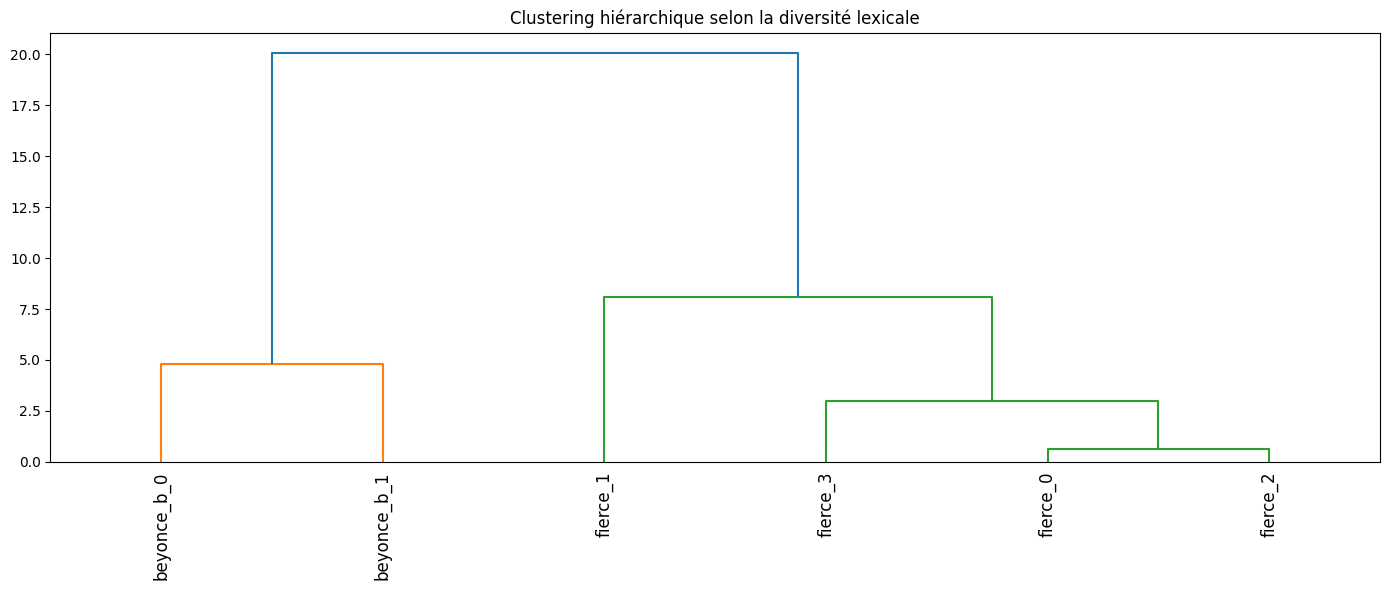

In [11]:
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

labels = list(lex_div_mtld.keys())
X = np.array(list(lex_div_mtld.values())).reshape(-1, 1)  # (n_chunks, 1)

Z = linkage(X, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=labels, leaf_rotation=90)
plt.title("Clustering hiérarchique selon la diversité lexicale")
plt.tight_layout()
plt.show()

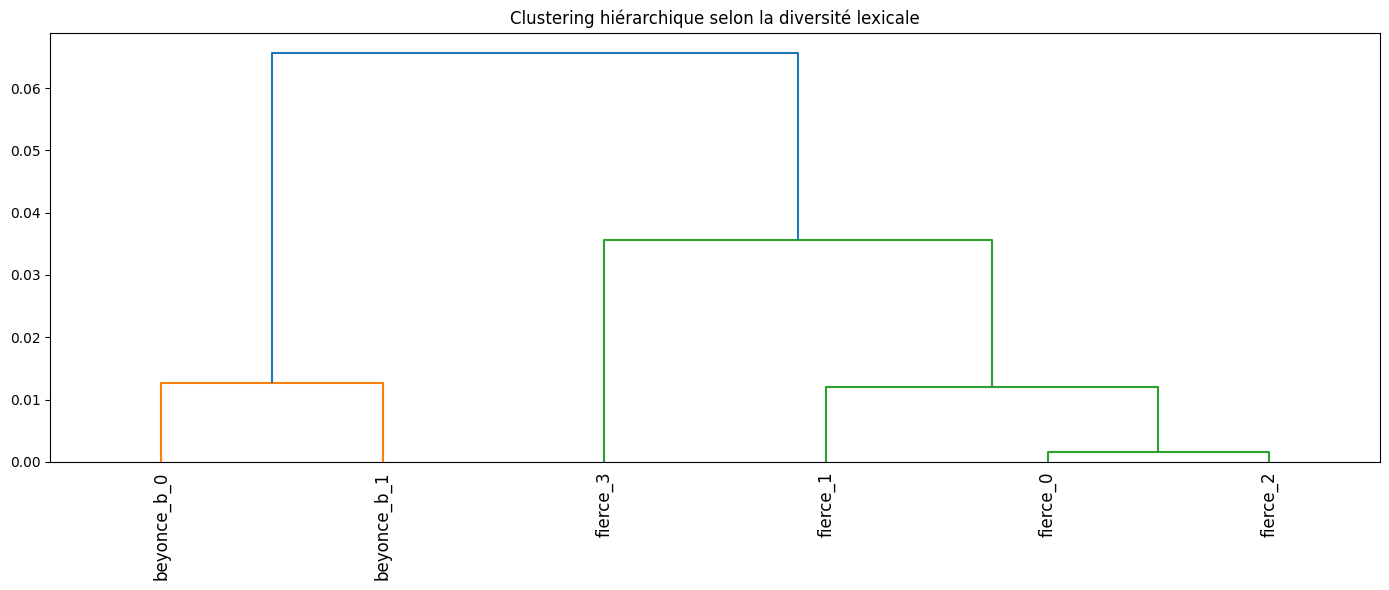

In [12]:
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

labels = list(lex_div_hdd.keys())
X = np.array(list(lex_div_hdd.values())).reshape(-1, 1)  # (n_chunks, 1)

Z = linkage(X, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=labels, leaf_rotation=90)
plt.title("Clustering hiérarchique selon la diversité lexicale")
plt.tight_layout()
plt.show()

In [17]:
lex_div_mtld

{'beyonce_b_0': 44.13403403081446,
 'beyonce_b_1': 39.339307048984466,
 'fierce_0': 28.348444444444443,
 'fierce_1': 34.394222595988644,
 'fierce_2': 28.979935445587415,
 'fierce_3': 26.099820146070556}

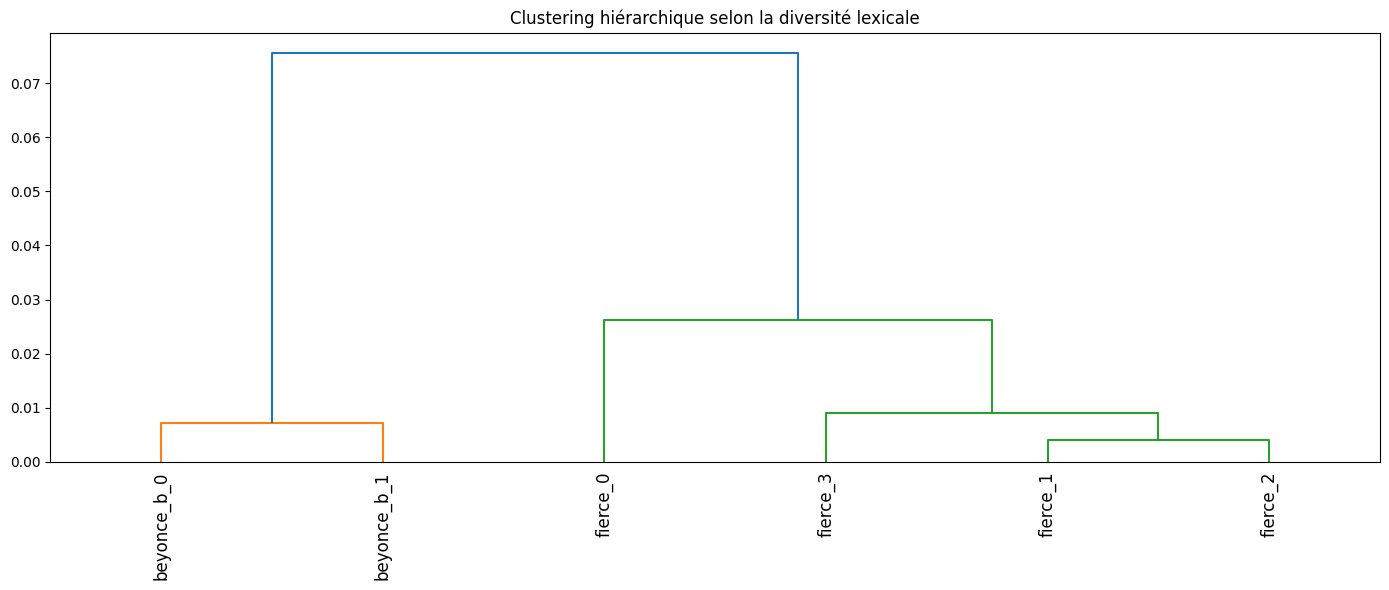

In [14]:
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

labels = list(lex_densite.keys())
X = np.array(list(lex_densite.values())).reshape(-1, 1)  # (n_chunks, 1)

Z = linkage(X, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=labels, leaf_rotation=90)
plt.title("Clustering hiérarchique selon la diversité lexicale")
plt.tight_layout()
plt.show()

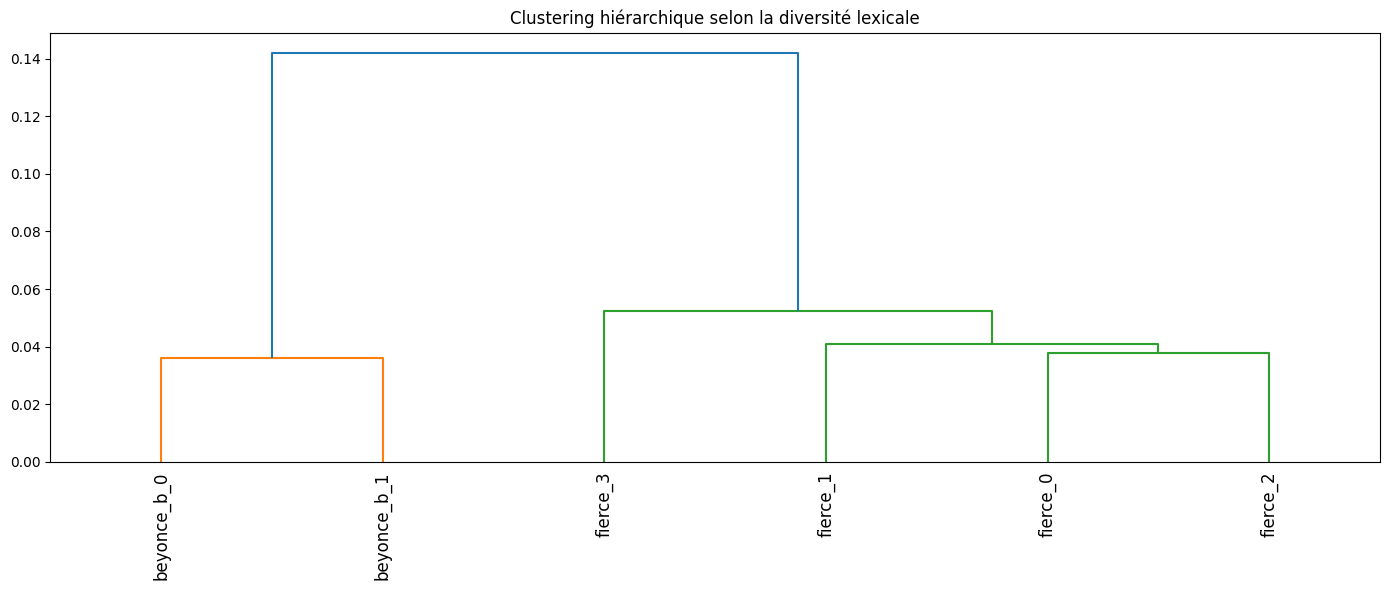

In [55]:
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

labels = list(bow_score.keys())
X = np.array(list(bow_score.values())).reshape(-1, len(voc_beyonce))  # (n_chunks, 1)

Z = linkage(X, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=labels, leaf_rotation=90)
plt.title("Clustering hiérarchique selon la diversité lexicale")
plt.tight_layout()
plt.show()

In [52]:
X = np.array(list(bow_score.values())).reshape(-1, 790)

In [53]:
X.shape

(6, 790)